# ADR Comparison Results Visualization

This notebook reads the ADR comparison results CSV and creates bar plots for each event showing:
- CCzero values for JN, JE, and JZ components
- Number of stations (n_stations) displayed on top of each bar
- Frequency range (fmin-fmax) in the title

## Notebook Overview
This notebook visualizes ROMY-vs-ADR comparison metrics across events and processing settings.

**Main workflow**
- Load aggregated ROMY/ADR comparison table(s).
- Clean and optionally complete event coverage.
- Plot key metrics (e.g., CC, RMSE, TF measures).
- Compare metric behavior versus parameters/events.
- Save summary comparison figures.

## Imports

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import yaml

from obspy import UTCDateTime

In [2]:

# Load the results CSV
results_file = "./output/results_romy_adr_comparison.csv"
df = pd.read_csv(results_file)

print(f"Loaded {len(df)} rows from {results_file}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nFirst few rows:")
print(df.head())


Loaded 54 rows from ./output/results_romy_adr_comparison.csv

Columns: ['event', 'component', 'ccmax', 'cczero', 'ccmaxshift', 'maxdev', 'rmse', 'r_squared', 'em', 'pm', 'eg', 'pg', 'n_stations', 'fmin', 'fmax', 'magnitude', 'distance_km', 'backazimuth']

First few rows:
      event component  ccmax  cczero  ccmaxshift  maxdev  rmse  r_squared  \
0  20260420        JZ   0.95    0.95         0.0   34.59  1.30     0.9087   
1  20260420        JN   0.98    0.97        -0.4   17.58  0.95     0.9343   
2  20260420        JE   0.98    0.96        -0.4   12.06  1.17     0.9273   
3  20250513        JZ   0.88    0.88         0.0   55.36  0.04     0.7727   
4  20250513        JN   0.96    0.96        -0.2   24.27  0.03     0.9136   

     em    pm    eg    pg  n_stations  fmin  fmax  magnitude  distance_km  \
0  0.30  0.07  7.42  9.26           4  0.02   0.1        7.4      9144.40   
1  0.22  0.08  7.99  9.16           4  0.02   0.1        7.4      9144.40   
2  0.16  0.09  8.50  9.15         

In [3]:
def insert_missing_events(df, events_file="./event_list.yml"):

    # Load event list YAML
    with open(events_file, "r", encoding="utf-8") as f:
        y = yaml.safe_load(f)
    
    # Supports:
    # - ['20240422', '20240815']
    # - {'events': ['20240422', 'event_20240815']}
    raw_events = y["events"] if isinstance(y, dict) and "events" in y else y

    # Normalize names to YYYYMMDD strings
    event_ids = []
    for e in raw_events:
        s = str(e).strip()
        if s.startswith("event_"):
            s = s.replace("event_", "", 1)
        event_ids.append(s)

    # Choose the dataframe column that identifies events
    event_col = "event"   # <- change if your CSV uses another name, e.g. "event"

    # Make sure comparable type
    df[event_col] = df[event_col].astype(str)

    # Reindex to include all events from YAML; missing rows are filled with NaN
    df = (
        df.set_index(event_col)
        .reindex(event_ids)
        .rename_axis(event_col)
        .reset_index()
    )

    print(f"Rows after alignment: {len(df)}")
    print(df.head())

    return df

In [4]:
def insert_missing_events(df, events_file="./event_list.yml"):
    
    with open(events_file, "r", encoding="utf-8") as f:
        y = yaml.safe_load(f)

    raw_events = y["events"] if isinstance(y, dict) and "events" in y else y

    # Normalize to YYYYMMDD strings
    event_ids = []
    for e in raw_events:
        s = str(e).strip()
        if s.startswith("event_"):
            s = s.replace("event_", "", 1)
        event_ids.append(s)

    event_col = "event"
    comp_col = "component"

    df = df.copy()
    df[event_col] = df[event_col].astype(str)

    # components currently in your result table (e.g., JZ, JN, JE)
    components = sorted(df[comp_col].dropna().unique().tolist())

    # optional safety if duplicates of (event, component) exist
    df = df.drop_duplicates(subset=[event_col, comp_col], keep="first")

    # full target index: every event from YAML × every component
    target_index = pd.MultiIndex.from_product(
        [event_ids, components],
        names=[event_col, comp_col]
    )

    df = (
        df.set_index([event_col, comp_col])
          .reindex(target_index)
          .reset_index()
    )

    print(f"Rows after alignment: {len(df)}")
    print(df.head())
    return df

In [5]:
df = insert_missing_events(df, events_file="./events_list.yml")

Rows after alignment: 57
      event component  ccmax  cczero  ccmaxshift  maxdev  rmse  r_squared  \
0  20190514        JE    NaN     NaN         NaN     NaN   NaN        NaN   
1  20190514        JN    NaN     NaN         NaN     NaN   NaN        NaN   
2  20190514        JZ    NaN     NaN         NaN     NaN   NaN        NaN   
3  20230908        JE   0.94    0.93         0.2   30.88  0.53     0.8685   
4  20230908        JN   0.99    0.97         0.4   12.42  0.54     0.9366   

     em    pm    eg    pg  n_stations  fmin  fmax  magnitude  distance_km  \
0   NaN   NaN   NaN   NaN         NaN   NaN   NaN        NaN          NaN   
1   NaN   NaN   NaN   NaN         NaN   NaN   NaN        NaN          NaN   
2   NaN   NaN   NaN   NaN         NaN   NaN   NaN        NaN          NaN   
3  0.26  0.10  7.71  9.03         6.0  0.02   0.1        6.8      2526.01   
4  0.14  0.07  8.73  9.28         6.0  0.02   0.1        6.8      2526.01   

   backazimuth  
0          NaN  
1          NaN 

In [6]:
# Check if fmin and fmax are the same for all rows
unique_fmin = df['fmin'].dropna().unique()
unique_fmax = df['fmax'].dropna().unique()

print(f"\nUnique fmin values: {unique_fmin}")
print(f"Unique fmax values: {unique_fmax}")

if len(unique_fmin) == 1 and len(unique_fmax) == 1:
    fmin = unique_fmin[0]
    fmax = unique_fmax[0]
    print(f"\n✓ All rows have the same frequency range: fmin={fmin}, fmax={fmax}")
else:
    print(f"\n⚠ WARNING: Frequency ranges are not consistent across all rows!")
    print(f"  fmin values: {unique_fmin}")
    print(f"  fmax values: {unique_fmax}")
    # Use the most common values or first values
    fmin = unique_fmin[0]
    fmax = unique_fmax[0]
    print(f"  Using fmin={fmin}, fmax={fmax} for plotting")


Unique fmin values: [0.02]
Unique fmax values: [0.1]

✓ All rows have the same frequency range: fmin=0.02, fmax=0.1


## Create Bar Plots for Each Event

In [7]:
def plot_bars(
        df,
        y_col,
        x_col="event",
        component_col="component",
        components=None,
        fmin=None,
        fmax=None,
        ylabel=None,
        title=None,
        figsize=None,
        bar_width=0.25,
        spacing=0.0,
        annotate_n_stations=True,
        no_data_label="NO ADR DATA",
        date_fmt_x=True,
        rotation=35,
        savepath=None,
        dpi=300,
    ):
    """
    Grouped bar chart: x = unique values of x_col (e.g. event), y = df[y_col],
    one bar per component (JN, JE, JZ by default).

    Parameters
    ----------
    df : DataFrame
    y_col : str
        Numeric column to plot on the y-axis (e.g. 'rmse', 'cczero', 'maxdev').
    x_col : str
        Column used as categories on the x-axis (default 'event').
    component_col : str
        Column that splits each x into grouped bars (default 'component').
    components : list of str or None
        Order of components; default ['JN', 'JE', 'JZ'].
    fmin, fmax : optional
        If both set, appended to the default title.
    ylabel : str or None
        Defaults to y_col.
    title : str or None
        Full title; if None, built from y_col and optional band.
    date_fmt_x : bool
        If True and x_col looks like YYYYMMDD integers/strings, format ticks as YYYY-MM-DD.
    """
    if components is None:
        components = ["JN", "JE", "JZ"]

    df = df.copy()
    df[x_col] = df[x_col].astype(str)
    df[component_col] = df[component_col].astype(str)

    xs = sorted(df[x_col].unique())
    n_x = len(xs)

    if figsize is None:
        figsize = (max(12, n_x * 0.8), 6)

    x = np.arange(n_x)
    x_positions = {c: x + i * (bar_width + spacing) for i, c in enumerate(components)}
    colors = {"JN": "tab:blue", "JE": "tab:orange", "JZ": "tab:green"}
    group_center = x + bar_width

    fig, ax = plt.subplots(figsize=figsize)
    
    fs = 15

    y_data = {c: [] for c in components}
    n_stations_data = {c: [] for c in components}

    for xv in xs:
        part = df[df[x_col] == xv]
        for c in components:
            sub = part[part[component_col] == c]
            if len(sub) == 0:
                y_data[c].append(np.nan)
                n_stations_data[c].append(np.nan)
                continue
            val = sub[y_col].values[0]
            if pd.isna(val):
                y_data[c].append(np.nan)
                n_stations_data[c].append(np.nan)
            else:
                y_data[c].append(float(val))
                if "n_stations" in sub.columns:
                    n_stations_data[c].append(int(sub["n_stations"].values[0]))
                else:
                    n_stations_data[c].append(np.nan)

    for c in components:
        bars = ax.bar(
            x_positions[c],
            y_data[c],
            bar_width,
            label=c[-1],
            color=colors.get(c, None),
            alpha=0.8,
            edgecolor="black",
            linewidth=1.0,
            zorder=2,
        )
        if annotate_n_stations and "n_stations" in df.columns:
            for i, (bar, n_stat) in enumerate(zip(bars, n_stations_data[c])):
                if pd.notna(y_data[c][i]) and y_data[c][i] > 0 and pd.notna(n_stat):
                    h = bar.get_height()
                    ax.text(
                        bar.get_x() + bar.get_width() / 2.0,
                        h + 0.01 * (ax.get_ylim()[1] - ax.get_ylim()[0]) if ax.get_ylim()[1] > 0 else h +0.1,
                        f"{int(n_stat)}",
                        ha="center",
                        va="bottom",
                        fontsize=11,
                    )

    for i, xv in enumerate(xs):
        if all(pd.isna(y_data[c][i]) for c in components):
            y0 = 0.02 * (ax.get_ylim()[1] - ax.get_ylim()[0]) if ax.get_ylim()[1] > 0 else 0.02
            ax.text(
                group_center[i],
                y0,
                no_data_label,
                rotation=90,
                ha="center",
                va="bottom",
                fontsize=14,
                color="k",
                zorder=3,
            )

    if ylabel is None:
        ylabel = y_col
    ax.set_ylabel(ylabel, fontsize=fs)

    if title is None:
        band = ""
        if fmin is not None and fmax is not None:
            band = f" (f={fmin}-{fmax} Hz)"
        title = f"ROMY - ADR Comparison — {y_col.upper()}{band}"
    ax.set_title(title, fontsize=14, fontweight="bold")

    ax.set_xticks(x + bar_width + spacing)
    if date_fmt_x:
        try:
            tick_labels = [UTCDateTime(str(xv)).strftime("%Y-%m-%d") for xv in xs]
        except Exception:
            tick_labels = [str(xv) for xv in xs]
    else:
        tick_labels = [str(xv) for xv in xs]
    ax.set_xticklabels(tick_labels, rotation=rotation, ha="right")

    ax.set_xlim(-0.5, n_x)

    flat = [v for c in components for v in y_data[c]]
    if np.isfinite(np.nanmax(flat)):
        ymax = float(np.nanmax(flat))
        ax.set_ylim(0, ymax * 1.15)
    else:
        ax.set_ylim(0, 1)

    ax.yaxis.set_minor_locator(mpl.ticker.AutoMinorLocator())
    ax.grid(True, which="major", alpha=0.5, axis="y", linestyle="-", zorder=1)
    ax.grid(True, which="minor", alpha=0.3, axis="y", linestyle="--", zorder=0)
    ax.tick_params(axis="both", which="major", labelsize=11)
    ax.legend(loc="upper right", fontsize=fs - 3, ncol=3) #, bbox_to_anchor=(1.0, 1.08))
    ax.tick_params(axis="both", labelsize=fs-2)

    plt.tight_layout()
    if savepath is not None:
        plt.savefig(savepath, dpi=dpi, bbox_inches="tight")

    return fig, ax

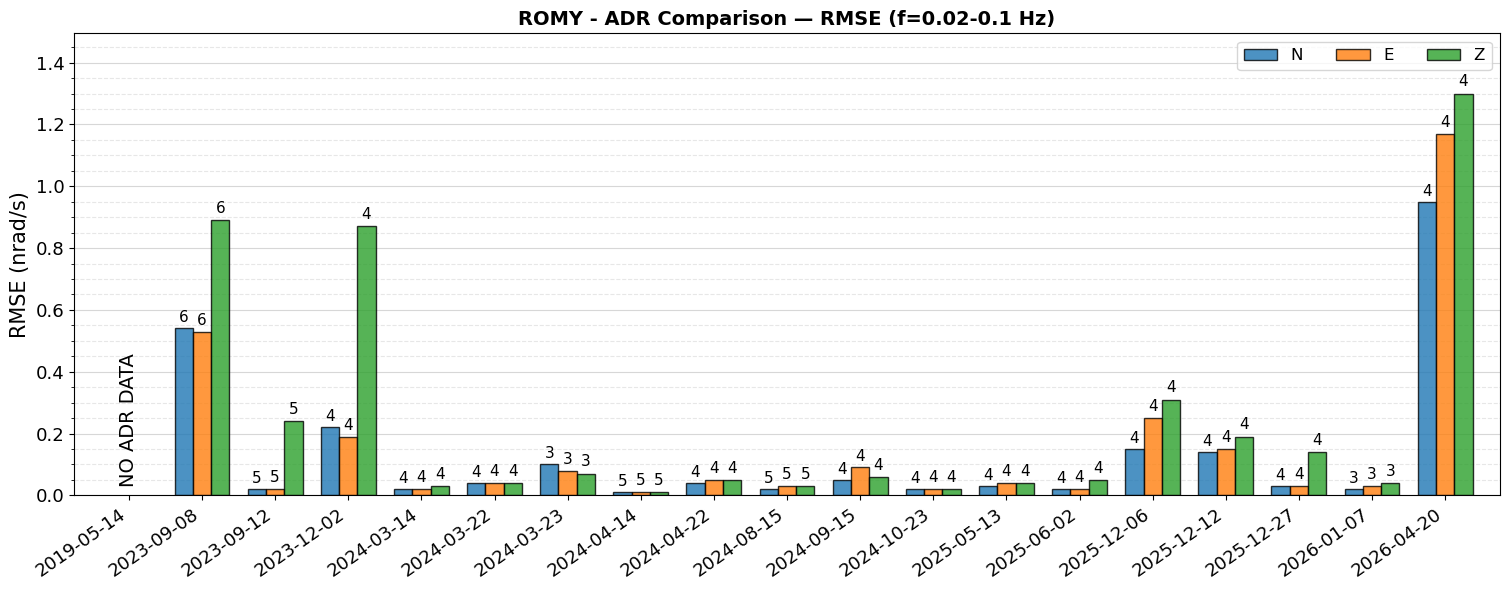

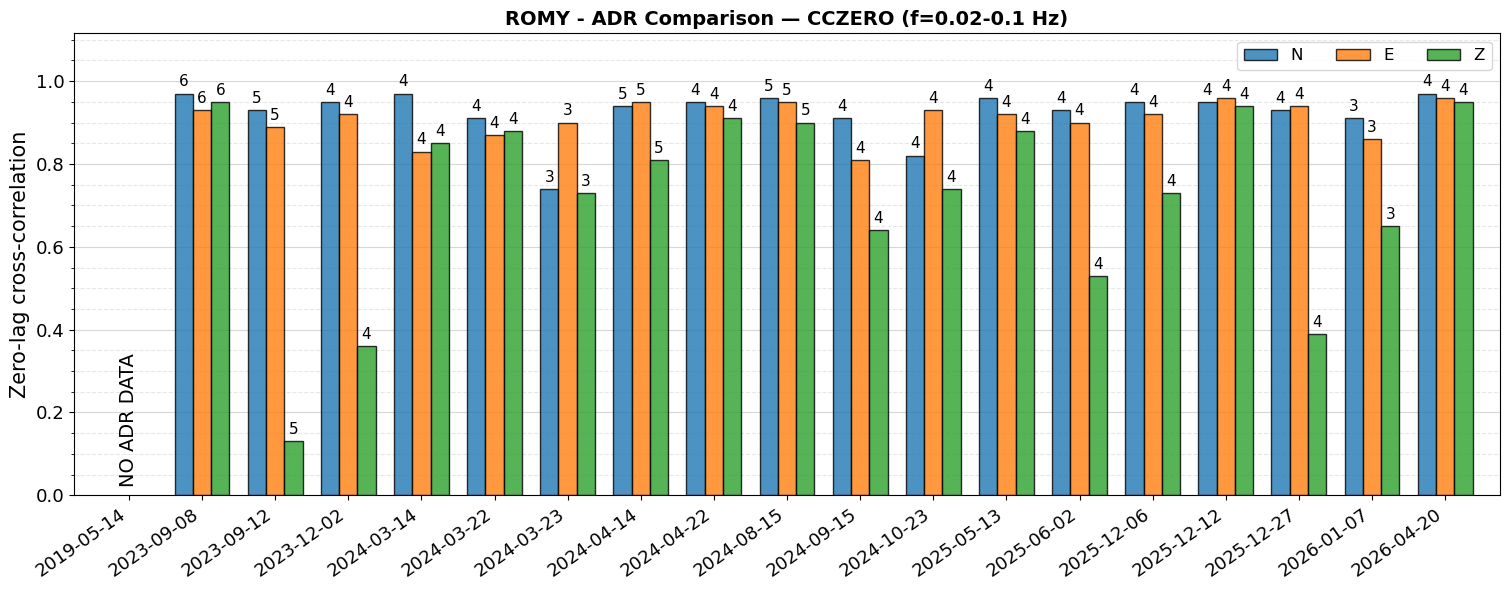

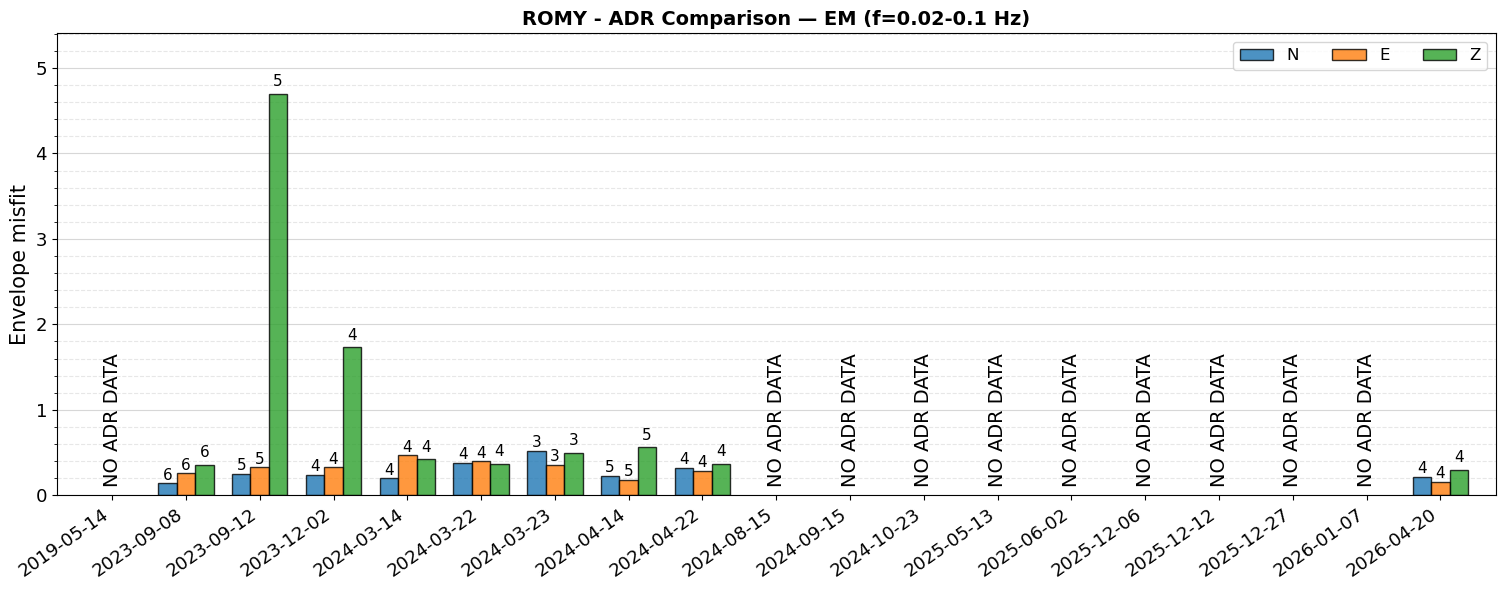

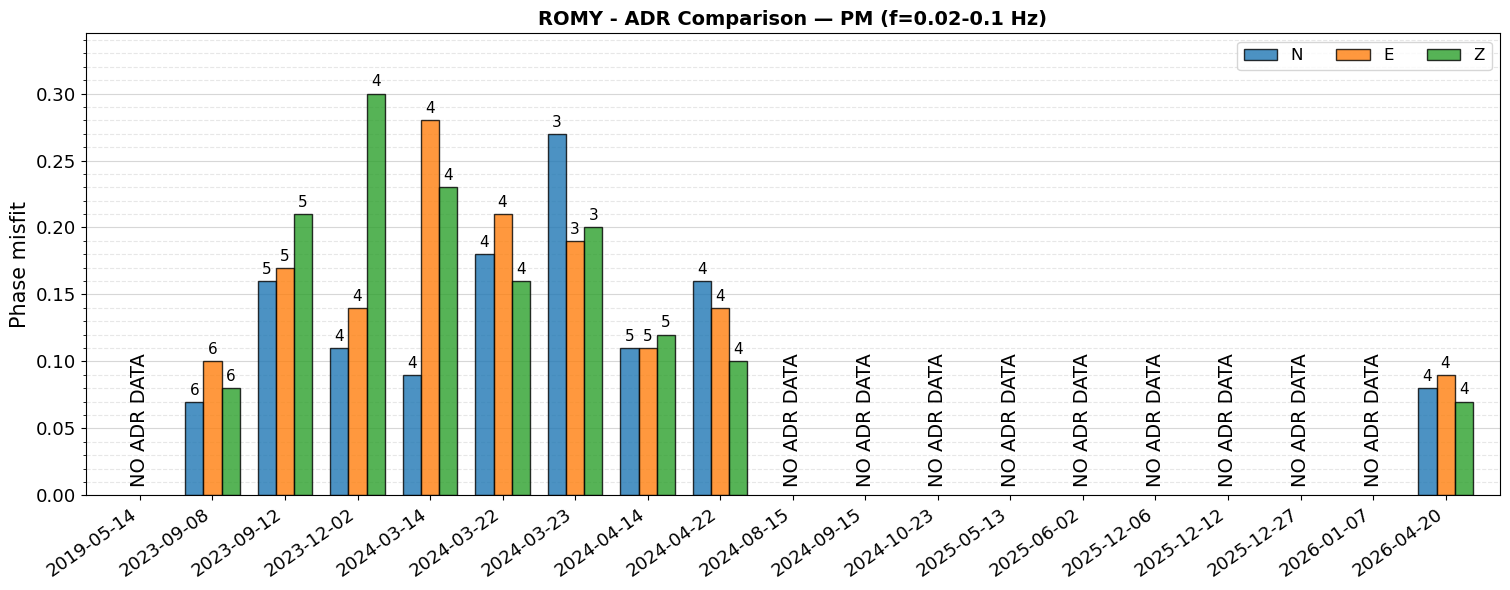

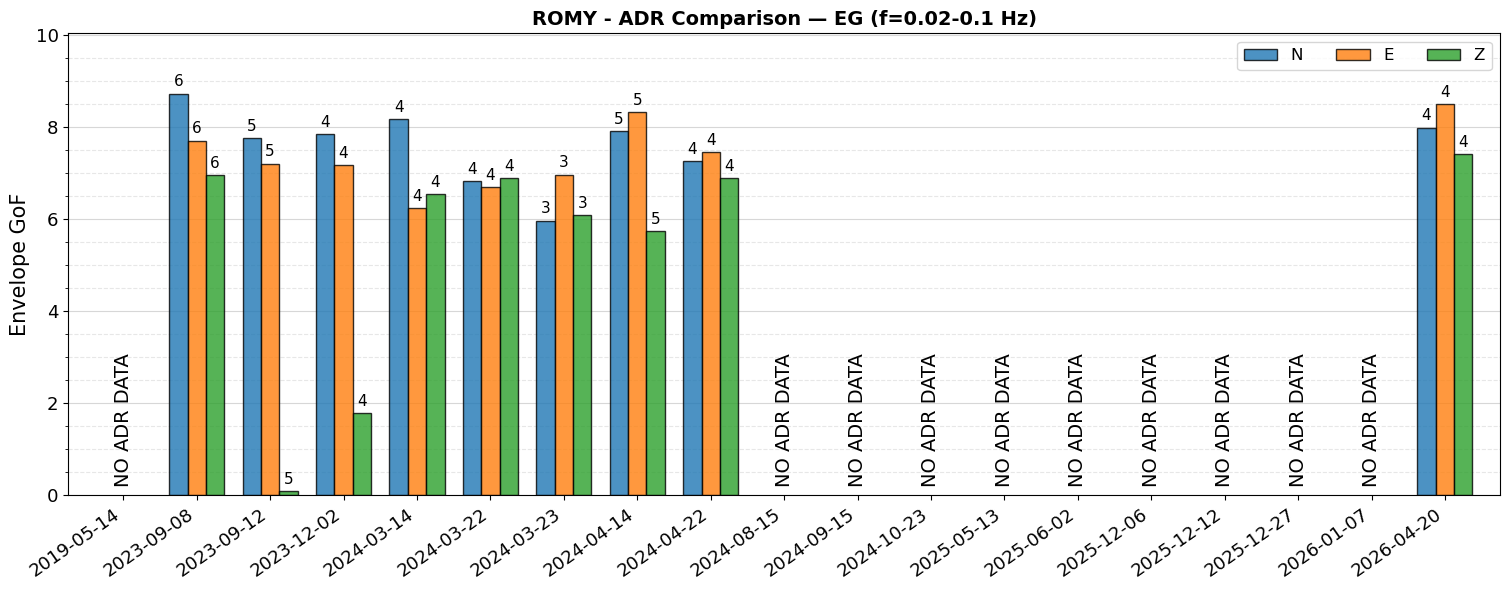

In [8]:
os.makedirs("./output/figures/adr", exist_ok=True)
# RMSE on y, events on x (same as your RMSE cell)
fig, ax = plot_bars(df, y_col="rmse", fmin=fmin, fmax=fmax, ylabel="RMSE (nrad/s)")
fig.savefig("./output/figures/adr/romy_adr_comparison_rmse.png", dpi=300, bbox_inches="tight")

# Zero-lag CC on y
fig, ax = plot_bars(df, y_col="cczero", fmin=fmin, fmax=fmax, ylabel="Zero-lag cross-correlation")
fig.savefig("./output/figures/adr/romy_adr_comparison_cczero.png", dpi=300, bbox_inches="tight")

# 
fig, ax = plot_bars(df, y_col="em", x_col="event", fmin=fmin, fmax=fmax, ylabel="Envelope misfit")
fig.savefig("./output/figures/adr/romy_adr_comparison_em.png", dpi=300, bbox_inches="tight")

# 
fig, ax = plot_bars(df, y_col="pm", x_col="event", fmin=fmin, fmax=fmax, ylabel="Phase misfit")
fig.savefig("./output/figures/adr/romy_adr_comparison_pm.png", dpi=300, bbox_inches="tight")

# 
fig, ax = plot_bars(df, y_col="eg", x_col="event", fmin=fmin, fmax=fmax, ylabel="Envelope GoF")
fig.savefig("./output/figures/adr/romy_adr_comparison_eg.png", dpi=300, bbox_inches="tight")


In [ ]:
# Plot phase versus envelope misfit
import os
from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap, BoundaryNorm

components_pm_em = ["JZ", "JN", "JE"]
panel_labels = ["(a)", "(b)", "(c)"]

df_plot = df.copy()
df_plot["event"] = df_plot["event"].astype(str)
df_plot = df_plot.dropna(subset=["pm", "em"])
df_plot["event_date"] = pd.to_datetime(df_plot["event"], format="%Y%m%d", errors="coerce")
df_plot = df_plot.dropna(subset=["event_date"])

events_sorted = (
    df_plot[["event", "event_date"]]
    .drop_duplicates("event")
    .sort_values("event_date")
    .reset_index(drop=True)
)
n_events = len(events_sorted)
event_to_idx = dict(zip(events_sorted["event"], range(n_events)))
df_plot["event_idx"] = df_plot["event"].map(event_to_idx)

if n_events <= 10:
    base_cmap = plt.get_cmap("tab10")
elif n_events <= 20:
    base_cmap = plt.get_cmap("tab20")
else:
    base_cmap = plt.get_cmap("turbo")

event_colors = base_cmap(np.linspace(0, 1, n_events, endpoint=False))
event_cmap = ListedColormap(event_colors)
event_norm = BoundaryNorm(np.arange(n_events + 1) - 0.5, n_events)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=False)
fs = 13

for ax, comp, panel in zip(axes, components_pm_em, panel_labels):
    sub = df_plot[df_plot["component"] == comp]
    if sub.empty:
        ax.set_title(comp[-1], fontsize=fs)
        ax.text(0.03, 0.95, panel, transform=ax.transAxes, fontsize=12, va="top")
        continue

    ax.scatter(
        sub["pm"],
        sub["em"],
        c=sub["event_idx"],
        cmap=event_cmap,
        norm=event_norm,
        s=55,
        edgecolors="k",
        linewidths=0.4,
        alpha=0.9,
        zorder=3,
    )

    x_max = sub["pm"].max()
    y_max = sub["em"].max()
    x_pad = max(0.02, 0.08 * x_max) if pd.notna(x_max) else 0.02
    y_pad = max(0.02, 0.08 * y_max) if pd.notna(y_max) else 0.02
    ax.set_xlim(-x_pad, x_max + x_pad)
    ax.set_ylim(-y_pad, y_max + y_pad)

    ax.set_xlabel("Phase misfit", fontsize=fs)
    if ax is axes[0]:
        ax.set_ylabel("Envelope misfit", fontsize=fs)
    ax.set_title(comp[-1], fontsize=fs, fontweight="bold")
    ax.grid(True, which="both", alpha=0.35, linestyle="--", zorder=0)
    ax.tick_params(axis="both", labelsize=fs - 2)
    ax.text(0.03, 0.95, panel, transform=ax.transAxes, fontsize=12, va="top")

sm = ScalarMappable(cmap=event_cmap, norm=event_norm)
sm.set_array([])
cbar = fig.colorbar(
    sm,
    ax=axes,
    pad=0.02,
    fraction=0.046,
    ticks=range(n_events),
)
date_labels = events_sorted["event_date"].dt.strftime("%Y-%m-%d")
cbar.ax.set_yticklabels(date_labels, fontsize=max(fs - 4, 7))
cbar.set_label("Event date", fontsize=fs)

fig.suptitle(
    f"Phase vs envelope misfit by event (f={fmin}-{fmax} Hz)",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
fig.subplots_adjust(right=0.82, top=0.88)

output_file = "./output/figures/adr/adr_comparison_pm_vs_em_by_component.png"
os.makedirs(os.path.dirname(output_file), exist_ok=True)
fig.savefig(output_file, dpi=300, bbox_inches="tight")
print(f"Saved figure to: {output_file}")

plt.show()

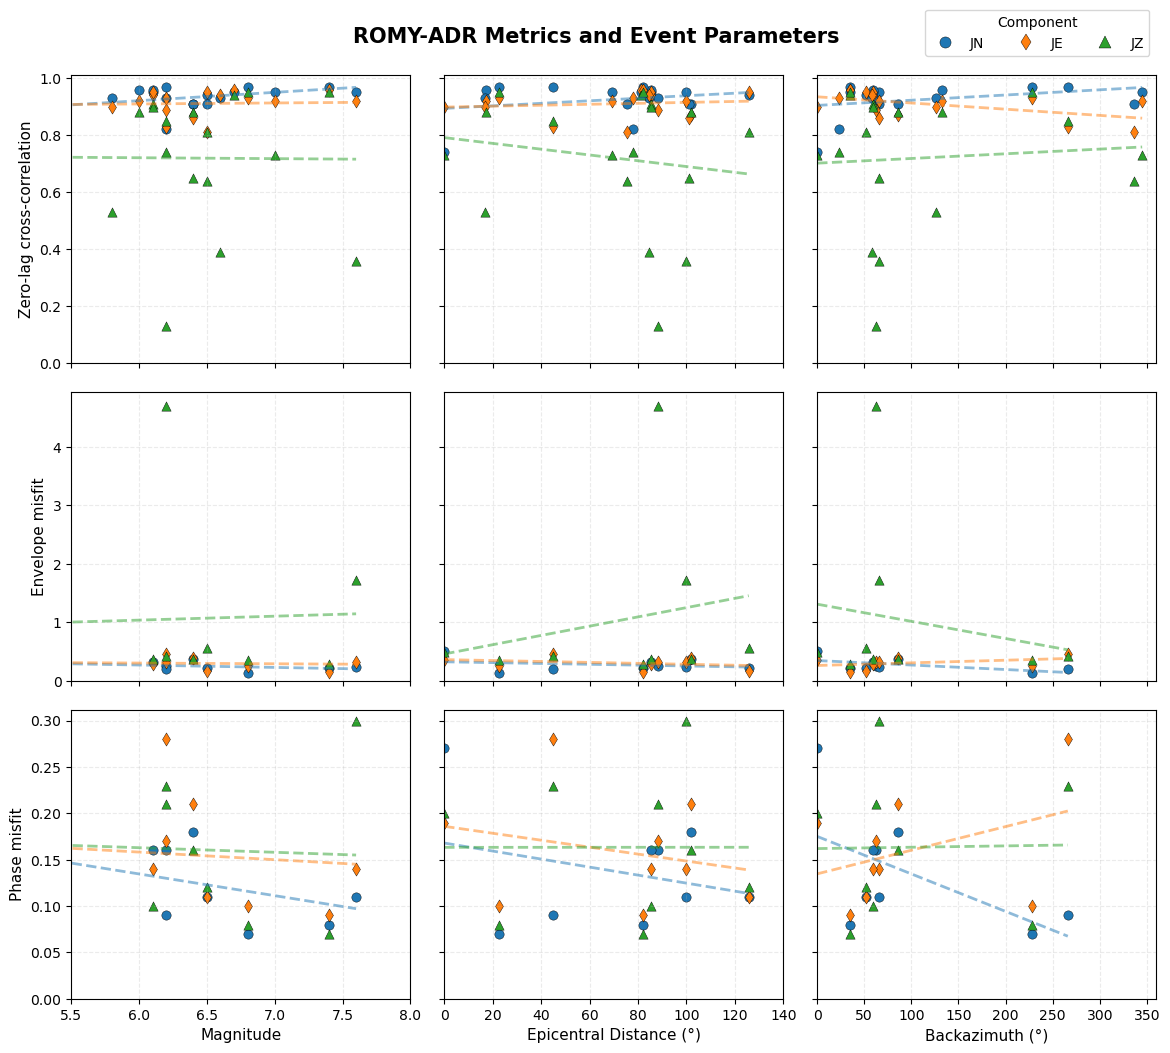

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# If your df has distance in km:
# 1 degree ~ 111.19 km along Earth's surface
df["epicentral_distance_deg"] = df["distance_km"] / 111.19

# Columns = x variables
x_cols = ["magnitude", "epicentral_distance_deg", "backazimuth"]

# Rows = y variables
y_cols = ["cczero", "em", "pm"]

component_col = "component"
colors = {"JN": "tab:blue", "JE": "tab:orange", "JZ": "tab:green"}
markers = {"JN": "o", "JE": "d", "JZ": "^"}  # circle, diamond, triangle

label_map = {
    "magnitude": "Magnitude",
    "epicentral_distance_deg": "Epicentral Distance (°)",
    "backazimuth": "Backazimuth (°)",
    "cczero": "Zero-lag cross-correlation",
    "em": "Envelope misfit",
    "pm": "Phase misfit",
}

# Set x-limits per x quantity (adjust values as needed)
xlims = {
    "magnitude": (5.5, 8.),
    "epicentral_distance_deg": (0, 140),
    "backazimuth": (0, 360),
}

fig, axes = plt.subplots(
    nrows=len(y_cols),
    ncols=len(x_cols),
    figsize=(14, 12),
    sharex="col",
    sharey="row"
)

plt.subplots_adjust(wspace=0.1, hspace=0.1)

for i, y_col in enumerate(y_cols):
    for j, x_col in enumerate(x_cols):
        ax = axes[i, j]

        for comp in colors.keys():
            sub = df[df[component_col] == comp][[x_col, y_col]].dropna()
            if len(sub) == 0:
                continue

            x = sub[x_col].to_numpy(dtype=float)
            y = sub[y_col].to_numpy(dtype=float)

            # Scatter with component-specific marker + color
            ax.scatter(
                x, y,
                s=45,
                alpha=1.0,
                color=colors[comp],
                marker=markers[comp],
                edgecolor="k",
                linewidth=0.3
            )

            # Linear trendline per component
            if len(x) >= 2 and np.nanstd(x) > 0:
                m, b = np.polyfit(x, y, 1)
                xx = np.linspace(np.nanmin(x), np.nanmax(x), 100)
                yy = m * xx + b
                ax.plot(xx, yy, color=colors[comp], linewidth=2, ls="--", alpha=0.5)

        # Apply x-limit for this x quantity
        if x_col in xlims:
            ax.set_xlim(*xlims[x_col])

        # if i == 0:
        #     ax.set_title(label_map.get(x_col, x_col), fontsize=12, fontweight="bold")
        if i == len(y_cols) - 1:
            ax.set_xlabel(label_map.get(x_col, x_col), fontsize=11)
        if j == 0:
            ax.set_ylabel(label_map.get(y_col, y_col), fontsize=11)

        ax.grid(True, alpha=0.25, linestyle="--")

        ax.set_ylim(bottom=0)

# Custom legend to show both color + marker per component
legend_handles = [
    Line2D(
        [0], [0],
        marker=markers[c],
        color="w",
        markerfacecolor=colors[c],
        markeredgecolor="k",
        markeredgewidth=0.3,
        markersize=8,
        label=c
    )
    for c in colors.keys()
]

fig.legend(
    handles=legend_handles,
    title="Component",
    loc="upper right",
    bbox_to_anchor=(0.9, 0.94),
    ncol=3,
    frameon=True
)

fig.suptitle("ROMY-ADR Metrics and Event Parameters", fontsize=15, fontweight="bold", y=0.92)
plt.show()

fig.savefig("./output/figures/adr/romy_adr_comparison_metrics_vs_parameters.png", dpi=300, bbox_inches="tight")

Saved figure to: ./output/figures/adr_comparison_results_cczero_em_pm.png


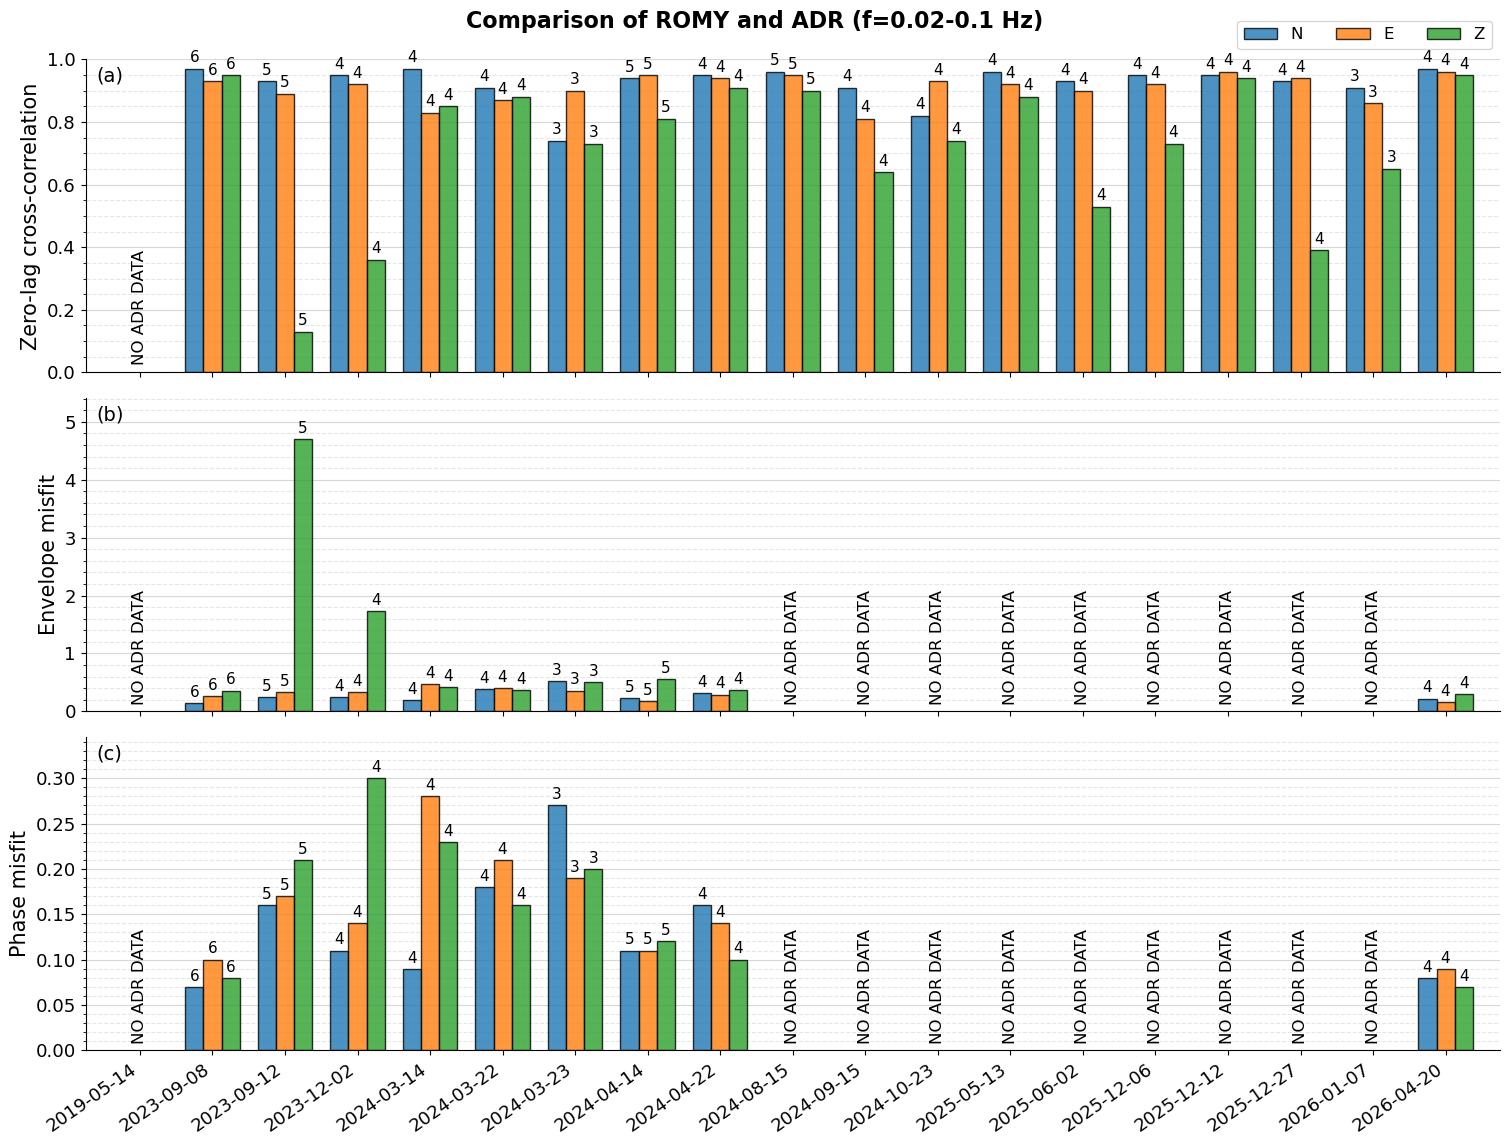

In [10]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from obspy import UTCDateTime
import os

# -----------------------------
# Config
# -----------------------------
components = ["JN", "JE", "JZ"]
component_col = "component"
x_col = "event"
y_cols = ["cczero", "em", "pm"]  # a, b, c
ylabels = {
    "cczero": "Zero-lag cross-correlation",
    "em": "Envelope misfit",
    "pm": "Phase misfit",
}
panel_labels = ["(a)", "(b)", "(c)"]

bar_width = 0.25
spacing = 0.0
date_fmt_x = True
rotation = 35
annotate_n_stations = True
no_data_label = "NO ADR DATA"

colors = {"JN": "tab:blue", "JE": "tab:orange", "JZ": "tab:green"}

# -----------------------------
# Prepare x axis
# -----------------------------
dfp = df.copy()
dfp[x_col] = dfp[x_col].astype(str)
dfp[component_col] = dfp[component_col].astype(str)

xs = sorted(dfp[x_col].unique())
n_x = len(xs)

x = np.arange(n_x)
x_positions = {c: x + i * (bar_width + spacing) for i, c in enumerate(components)}
group_center = x + bar_width

if date_fmt_x:
    try:
        tick_labels = [UTCDateTime(str(xv)).strftime("%Y-%m-%d") for xv in xs]
    except Exception:
        tick_labels = [str(xv) for xv in xs]
else:
    tick_labels = [str(xv) for xv in xs]

# -----------------------------
# Figure
# -----------------------------
fig, axes = plt.subplots(
    nrows=3, ncols=1,
    figsize=(max(12, n_x * 0.8), 12),
    sharex=True
)

fs = 15

for k, y_col in enumerate(y_cols):
    ax = axes[k]

    # collect data in same style as plot_bars()
    y_data = {c: [] for c in components}
    n_stations_data = {c: [] for c in components}

    for xv in xs:
        part = dfp[dfp[x_col] == xv]
        for c in components:
            sub = part[part[component_col] == c]
            if len(sub) == 0:
                y_data[c].append(np.nan)
                n_stations_data[c].append(np.nan)
                continue

            val = sub[y_col].values[0]
            if pd.isna(val):
                y_data[c].append(np.nan)
                n_stations_data[c].append(np.nan)
            else:
                y_data[c].append(float(val))
                if "n_stations" in sub.columns:
                    n_stations_data[c].append(int(sub["n_stations"].values[0]))
                else:
                    n_stations_data[c].append(np.nan)

    # bars
    for c in components:
        bars = ax.bar(
            x_positions[c],
            y_data[c],
            bar_width,
            label=c[-1],
            color=colors.get(c, None),
            alpha=0.8,
            edgecolor="black",
            linewidth=1.0,
            zorder=2,
        )

        # station counts
        if annotate_n_stations and "n_stations" in dfp.columns:
            # set y-limits before placing labels to stabilize vertical offset
            flat_tmp = [v for comp in components for v in y_data[comp]]
            if np.isfinite(np.nanmax(flat_tmp)):
                ymax_tmp = float(np.nanmax(flat_tmp))
                ax.set_ylim(0, ymax_tmp * 1.15 if ymax_tmp > 0 else 1)
            else:
                ax.set_ylim(0, 1)

            for i, (bar, n_stat) in enumerate(zip(bars, n_stations_data[c])):
                if pd.notna(y_data[c][i]) and y_data[c][i] > 0 and pd.notna(n_stat):
                    h = bar.get_height()
                    ax.text(
                        bar.get_x() + bar.get_width() / 2.0,
                        h + 0.01 * (ax.get_ylim()[1] - ax.get_ylim()[0]),
                        f"{int(n_stat)}",
                        ha="center",
                        va="bottom",
                        fontsize=11,
                    )

    # NO ADR DATA labels
    for i, xv in enumerate(xs):
        if all(pd.isna(y_data[c][i]) for c in components):
            y0 = 0.02 * (ax.get_ylim()[1] - ax.get_ylim()[0]) if ax.get_ylim()[1] > 0 else 0.02
            ax.text(
                group_center[i],
                y0,
                no_data_label,
                rotation=90,
                ha="center",
                va="bottom",
                fontsize=12,
                color="k",
                zorder=3,
            )

    # y formatting
    flat = [v for c in components for v in y_data[c]]
    if np.isfinite(np.nanmax(flat)):
        ymax = float(np.nanmax(flat))
        ax.set_ylim(0, ymax * 1.15 if ymax > 0 else 1)
    else:
        ax.set_ylim(0, 1)

    ax.set_ylabel(ylabels.get(y_col, y_col), fontsize=fs)
    ax.set_xlim(-0.5, n_x)
    ax.yaxis.set_minor_locator(mpl.ticker.AutoMinorLocator())
    ax.grid(True, which="major", alpha=0.5, axis="y", linestyle="-", zorder=1)
    ax.grid(True, which="minor", alpha=0.3, axis="y", linestyle="--", zorder=0)
    ax.tick_params(axis="both", labelsize=fs - 2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # panel label
    ax.text(0.008, 0.93, panel_labels[k], transform=ax.transAxes, fontsize=14)

axes[0].set_ylim(0, 1)

# x ticks only on bottom axis
axes[-1].set_xticks(x + bar_width + spacing)
axes[-1].set_xticklabels(tick_labels, rotation=rotation, ha="right")

# title + legend
fig.suptitle(f"Comparison of ROMY and ADR (f={fmin}-{fmax} Hz)", fontsize=16, fontweight="bold", y=0.95)
axes[0].legend(loc="upper right", fontsize=fs - 3, ncol=3, bbox_to_anchor=(1.0, 1.15))

plt.tight_layout(rect=[0, 0, 1, 0.98])

# Save figure (optional)
output_file = "./output/figures/publication/adr_comparison_results_cczero_em_pm.png"
os.makedirs("./output/figures/publication", exist_ok=True)
plt.savefig(output_file, dpi=300, bbox_inches="tight")
print(f"Saved figure to: {output_file}")

plt.show()

In [11]:
import pandas as pd

def build_latex_wide_table(
    df,
    metrics=("cczero", "em", "pm", "maxdev"),  # RMSE removed
    comp_order=("JN", "JE", "JZ"),
    rename_metric=None,
    round_map=None,  # e.g. {"EM": 2, ("PM", "JN"): 3}
    add_mean_row=True,
    mean_label="Mean",
):
    tmp = df.copy()
    tmp["event"] = tmp["event"].astype(str)

    metrics = [m for m in metrics if m in tmp.columns]

    # Pivot: rows=event, columns=(metric, component)
    wide = tmp.pivot_table(
        index="event",
        columns="component",
        values=metrics,
        aggfunc="first"
    )

    # Order components and metrics
    comps = [c for c in comp_order if c in wide.columns.get_level_values(1)]
    wide = wide.reindex(columns=comps, level=1)
    wide = wide.reindex(metrics, axis=1, level=0)

    # Pretty metric names
    if rename_metric is None:
        rename_metric = {
            "cczero": "CC$_0$",
            "em": "EM",
            "pm": "PM",
            "maxdev": "MaxDev",
        }

    wide.columns = pd.MultiIndex.from_tuples(
        [(rename_metric.get(m, m), c) for (m, c) in wide.columns]
    )

    # Rounding
    if round_map:
        for key, digits in round_map.items():
            # Specific subcolumn: ("EM", "JN") or ("em", "JN")
            if isinstance(key, tuple) and len(key) == 2:
                if key in wide.columns:
                    wide[key] = pd.to_numeric(wide[key], errors="coerce").round(digits)
                else:
                    raw_m, comp = key
                    mapped = (rename_metric.get(raw_m, raw_m), comp)
                    if mapped in wide.columns:
                        wide[mapped] = pd.to_numeric(wide[mapped], errors="coerce").round(digits)
                continue

            # Top-level metric: "EM" or "em"
            top = key
            top_mapped = rename_metric.get(top, top)
            targets = [c for c in wide.columns if c[0] in (top, top_mapped)]
            for c in targets:
                wide[c] = pd.to_numeric(wide[c], errors="coerce").round(digits)

    # Event index formatting (YYYYMMDD -> YYYY-MM-DD)
    try:
        wide.index = pd.to_datetime(wide.index, format="%Y%m%d").strftime("%Y-%m-%d")
    except Exception:
        pass
    wide.index.name = "Event"

    # Append a mean row across events (per metric/component column)
    if add_mean_row:
        numeric_wide = wide.apply(pd.to_numeric, errors="coerce")
        mean_vals = numeric_wide.mean(axis=0, skipna=True)
        if round_map:
            for col in numeric_wide.columns:
                top = col[0]
                digits = None
                if col in round_map:
                    digits = round_map[col]
                elif top in round_map:
                    digits = round_map[top]
                else:
                    for raw_m, pretty in (rename_metric or {}).items():
                        if pretty == top and raw_m in round_map:
                            digits = round_map[raw_m]
                            break
                if digits is not None:
                    mean_vals[col] = round(mean_vals[col], digits)
        mean_row = pd.DataFrame([mean_vals], index=[mean_label], columns=wide.columns)
        mean_row.index.name = wide.index.name
        wide = pd.concat([wide, mean_row])

    return wide


# ------------------------
# Build table
# ------------------------
round_map = {
    "CC$_0$": 2,
    "EM": 2,
    "PM": 2,
    "MaxDev": 0,
    # optional per-subcolumn override:
    # ("EM", "JN"): 3,
}

wide = build_latex_wide_table(
    df,
    metrics=("cczero", "em", "pm", "maxdev"),
    round_map=round_map
)

# Build LaTeX formatters to enforce fixed decimals in output
fmt = {}
for key, digits in round_map.items():
    if isinstance(key, tuple):
        # direct or mapped tuple
        if key in wide.columns:
            fmt[key] = (lambda n: (lambda x: "--" if pd.isna(x) else f"{x:.{n}f}"))(digits)
        else:
            raw_m, comp = key
            mapped = ({"cczero": "CC$_0$", "em": "EM", "pm": "PM", "maxdev": "MaxDev"}.get(raw_m, raw_m), comp)
            if mapped in wide.columns:
                fmt[mapped] = (lambda n: (lambda x: "--" if pd.isna(x) else f"{x:.{n}f}"))(digits)
    else:
        top = key
        top_mapped = {"cczero": "CC$_0$", "em": "EM", "pm": "PM", "maxdev": "MaxDev"}.get(top, top)
        for col in wide.columns:
            if col[0] in (top, top_mapped):
                fmt[col] = (lambda n: (lambda x: "--" if pd.isna(x) else f"{x:.{n}f}"))(digits)

latex_str = wide.to_latex(
    escape=False,
    na_rep="--",
    multicolumn=True,
    multirow=True,
    formatters=fmt,
    caption="ROMY-ADR metrics by event with component subcolumns.",
    label="tab:romy_adr_wide_no_rmse",
)

print(latex_str)

# Optional save:
# with open("./output/tables/romy_adr_wide_no_rmse.tex", "w") as f:
#     f.write(latex_str)

\begin{table}
\centering
\caption{ROMY-ADR metrics by event with component subcolumns.}
\label{tab:romy_adr_wide_no_rmse}
\begin{tabular}{lrrrrrrrrrrrr}
\toprule
{} & \multicolumn{3}{l}{CC$_0$} & \multicolumn{3}{l}{EM} & \multicolumn{3}{l}{PM} & \multicolumn{3}{l}{MaxDev} \\
{} &     JN &   JE &   JZ &   JN &   JE &   JZ &   JN &   JE &   JZ &     JN & JE &   JZ \\
Event      &        &      &      &      &      &      &      &      &      &        &    &      \\
\midrule
2023-09-08 &   0.97 & 0.93 & 0.95 & 0.14 & 0.26 & 0.36 & 0.07 & 0.10 & 0.08 &     12 & 31 &   38 \\
2023-09-12 &   0.93 & 0.89 & 0.13 & 0.25 & 0.33 & 4.70 & 0.16 & 0.17 & 0.21 &     23 & 42 & 1370 \\
2023-12-02 &   0.95 & 0.92 & 0.36 & 0.24 & 0.33 & 1.73 & 0.11 & 0.14 & 0.30 &     24 & 26 &  103 \\
2024-03-14 &   0.97 & 0.83 & 0.85 & 0.20 & 0.47 & 0.42 & 0.09 & 0.28 & 0.23 &     21 & 38 &   68 \\
2024-03-22 &   0.91 & 0.87 & 0.88 & 0.38 & 0.40 & 0.37 & 0.18 & 0.21 & 0.16 &     59 & 55 &   38 \\
2024-03-23 &   0.74 & 0

/tmp/ipykernel_7848/2093275058.py:134: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  latex_str = wide.to_latex(
